# BEAM RL task, 70/30 version: simulation and parameter recovery

Same analysis as `Simulation_and_Parameter_Recovery.ipynb`, but the good arm in each bandit wins **70%** of the time
and the bad arm **30%** (instead of 75% / 25%). Everything else is unchanged: **50 trials per bandit, randomly
interleaved, 100 trials total**, Rescorla-Wagner Q-learning with a softmax choice rule, the same parameter sets
and the same seeds.

Outputs go to `outputs/70_30/`, so the 75/25 results in `outputs/` are left as they are.
The side-by-side comparison of the two versions is in `Compare_75_25_vs_70_30.ipynb`.

1. Simulates the ten paired (α, β) groups and plots learning, with 10 and with 100 agents per group.
2. Runs parameter recovery on those paired groups.
3. Runs parameter recovery on a crossed α × β grid, so the two parameters vary independently.
4. Compares recovery for the 100-trial task against a 200-trial task.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

import beam_rl as rl

SEED = 10  # same seeds as the 75/25 notebook, so the two runs are directly comparable

# 70/30 version of the task: the good arm wins 70% of the time, the bad arm 30%.
P_GOOD, P_BAD = 0.70, 0.30
OUT = "outputs/70_30"
os.makedirs(OUT, exist_ok=True)

alpha_parameters = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00]
beta_parameters = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5]

## 1. Learning in the ten paired groups

Group *i* uses `alpha_parameters[i]` with `beta_parameters[i]`, as in the original notebook.
Curves are plotted against the **within-bandit trial (1–50)**, i.e. the number of times that bandit has been shown,
since a bandit's Q-values only change on its own trials.

In [2]:
# Learning curves for the ten paired (alpha, beta) groups.
# 10 agents per group matches the original notebook.
# 100 agents per group is the extra sample that smooths the noisier
# high-alpha and high-beta curves. Both still use 50 trials per bandit.
def simulate_paired_groups(agents_per_group, seed):
    rng = np.random.default_rng(seed)
    alphas = np.repeat(alpha_parameters, agents_per_group)
    betas = np.repeat(beta_parameters, agents_per_group)
    data = rl.simulate_group(alphas, betas, rng, p_good=P_GOOD, p_bad=P_BAD)
    data["group"] = (data["agent"] - 1) // agents_per_group
    return data

sim_10 = simulate_paired_groups(10, SEED)
sim_100 = simulate_paired_groups(100, SEED)

# every agent should have 100 trials, 50 per bandit
for name, data in [("10 per group", sim_10), ("100 per group", sim_100)]:
    counts = data.groupby(["agent", "pair"]).size().unstack()
    assert (counts == rl.TRIALS_PER_PAIR).all().all()
    print(f"{name}: {data['agent'].nunique()} agents, {len(data)} observations, "
          f"{rl.TRIALS_PER_PAIR} trials per bandit for every agent")

sim_100.round(3).to_csv(f"{OUT}/simulated_trials_100_per_group.csv", index=False)


10 per group: 100 agents, 10000 observations, 50 trials per bandit for every agent
100 per group: 1000 agents, 100000 observations, 50 trials per bandit for every agent


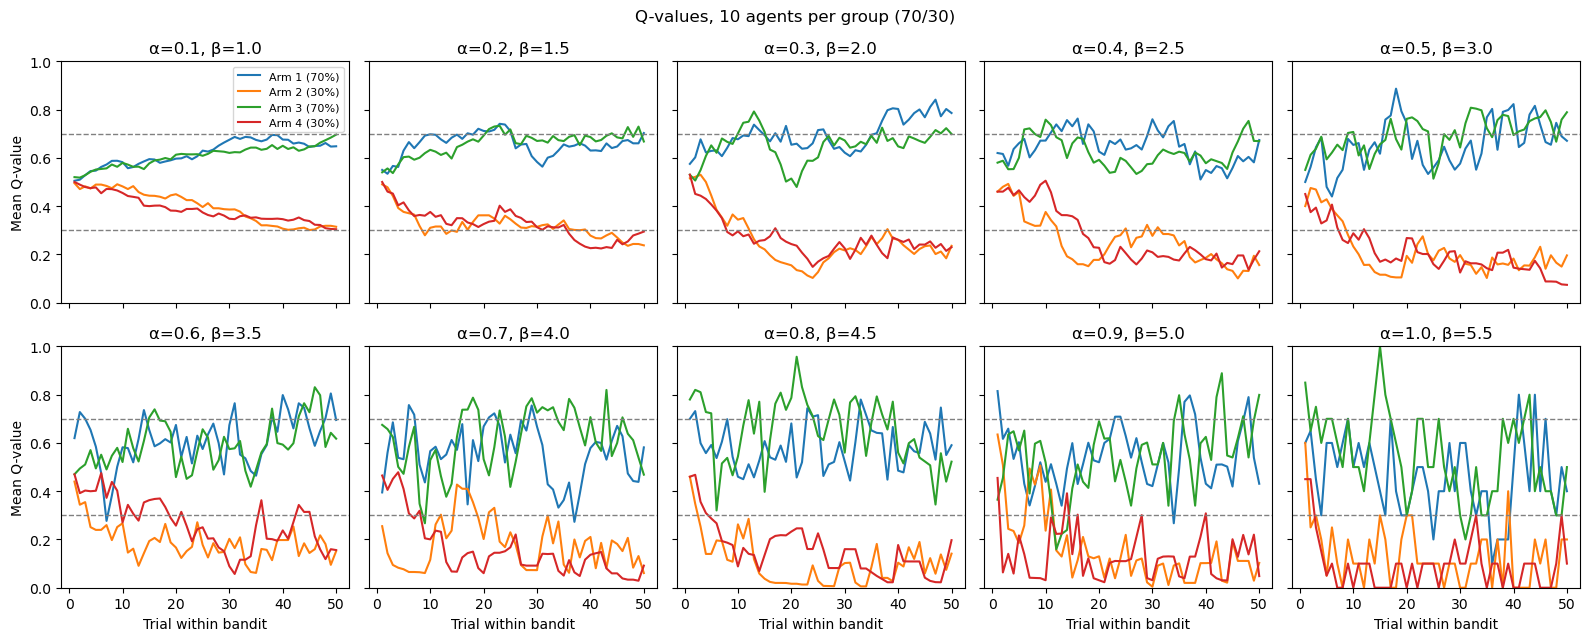

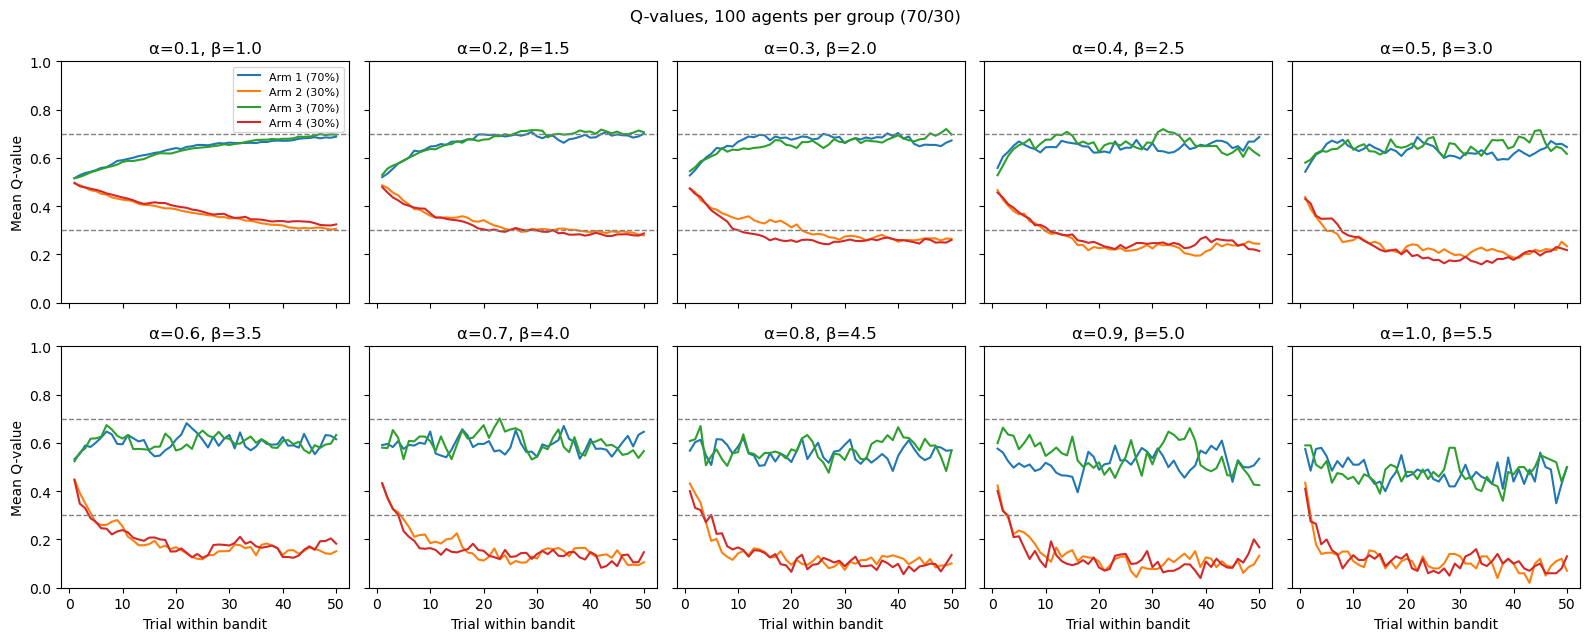

In [3]:
ARMS = [("Q_arm1", 1, "Arm 1 (70%)", "C0"), ("Q_arm2", 1, "Arm 2 (30%)", "C1"),
        ("Q_arm3", 2, "Arm 3 (70%)", "C2"), ("Q_arm4", 2, "Arm 4 (30%)", "C3")]

def plot_q_values(data, title, filename):
    fig, axes = plt.subplots(2, 5, figsize=(16, 6.5), sharex=True, sharey=True)
    for group, ax in enumerate(axes.flat):
        rows = data[data["group"] == group]
        for column, pair, label, color in ARMS:
            # a bandit's Q-values are only read on that bandit's own trials
            curve = rows[rows["pair"] == pair].groupby("pair_trial")[column].mean()
            ax.plot(curve.index, curve.values, label=label, color=color)
        ax.axhline(P_GOOD, linestyle="--", linewidth=1, color="grey")
        ax.axhline(P_BAD, linestyle="--", linewidth=1, color="grey")
        ax.set_title(f"α={alpha_parameters[group]}, β={beta_parameters[group]}")
        ax.set_ylim(0, 1)
    for ax in axes[1]:
        ax.set_xlabel("Trial within bandit")
    for ax in axes[:, 0]:
        ax.set_ylabel("Mean Q-value")
    axes.flat[0].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(filename, dpi=150)
    plt.show()

plot_q_values(sim_10, "Q-values, 10 agents per group (70/30)", f"{OUT}/q_values_10_per_group.png")
plot_q_values(sim_100, "Q-values, 100 agents per group (70/30)", f"{OUT}/q_values_100_per_group.png")

Going from 10 to 100 agents per group smooths the group means. As in the 75/25 version, the high-α/high-β groups
have mean Q-values below the true reward probabilities, because these agents leave an arm right after a loss and its
Q-value stays frozen at that loss until they come back.

The choice curves below are closer to what we will see in behaviour.


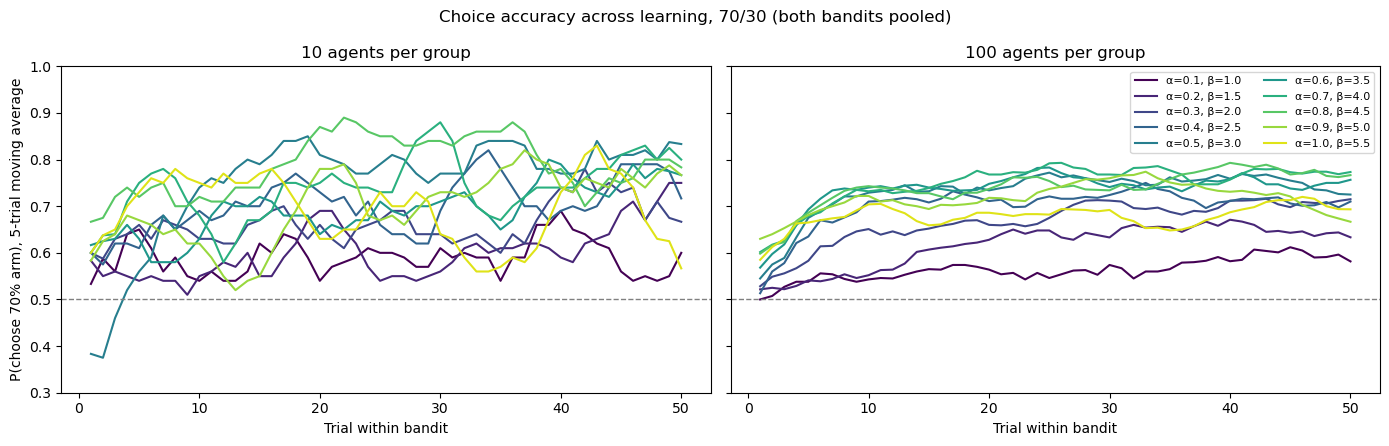

,alpha,beta,accuracy,win_rate,accuracy_last_10
group,,,,,
0,0.1,1.0,0.564,0.530,0.598
1,0.2,1.5,0.616,0.556,0.644
2,0.3,2.0,0.667,0.565,0.711
3,0.4,2.5,0.699,0.578,0.713
4,0.5,3.0,0.730,0.595,0.751
5,0.6,3.5,0.735,0.590,0.748
6,0.7,4.0,0.748,0.596,0.776
7,0.8,4.5,0.738,0.595,0.777
8,0.9,5.0,0.716,0.588,0.702


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.95, 10))
for ax, data, title in [(axes[0], sim_10, "10 agents per group"), (axes[1], sim_100, "100 agents per group")]:
    for group in range(10):
        curve = data[data["group"] == group].groupby("pair_trial")["chose_good"].mean()
        smooth = curve.rolling(5, center=True, min_periods=1).mean()
        ax.plot(smooth.index, smooth.values, color=colors[group],
                label=f"α={alpha_parameters[group]}, β={beta_parameters[group]}")
    ax.axhline(0.5, linestyle="--", linewidth=1, color="grey")
    ax.set_title(title)
    ax.set_xlabel("Trial within bandit")
    ax.set_ylim(0.3, 1)
axes[0].set_ylabel("P(choose 70% arm), 5-trial moving average")
axes[1].legend(fontsize=8, ncol=2)
fig.suptitle("Choice accuracy across learning, 70/30 (both bandits pooled)")
fig.tight_layout()
fig.savefig(f"{OUT}/choice_accuracy.png", dpi=150)
plt.show()

summary = sim_100.groupby("group").agg(alpha=("alpha", "first"), beta=("beta", "first"),
                                       accuracy=("chose_good", "mean"),
                                       win_rate=("outcome", "mean")).round(3)
late = sim_100[sim_100["pair_trial"] > 40].groupby("group")["chose_good"].mean().round(3)
summary["accuracy_last_10"] = late
summary

## 2. Parameter recovery on the paired groups

Each simulated agent is refit by maximum likelihood (coarse grid search for a starting point, then L-BFGS-B with
0 ≤ α ≤ 1 and 0 ≤ β ≤ 20). We then compare the fitted values against the values that generated the data.

When true α is at or near 1 the Q-values are just the last outcome (0 or 1), the likelihood is nearly flat in β, and the β estimate often runs off to large values. Read the β medians, not the means or SDs.

In [5]:
# Parameter recovery on the paired groups: 100 agents at each (alpha, beta)
# pair, simulated on the 100-trial task, then refit from choices and outcomes.
def recovery_stats(results):
    return {"alpha_pearson": pearsonr(results["alpha_true"], results["alpha_hat"])[0],
            "alpha_spearman": spearmanr(results["alpha_true"], results["alpha_hat"])[0],
            "beta_pearson": pearsonr(results["beta_true"], results["beta_hat"])[0],
            "beta_spearman": spearmanr(results["beta_true"], results["beta_hat"])[0],
            "beta_at_upper_bound": (results["beta_hat"] > rl.BETA_BOUNDS[1] - 0.01).mean(),
            "alpha_at_a_bound": ((results["alpha_hat"] < 0.01) | (results["alpha_hat"] > 0.99)).mean()}

rng = np.random.default_rng(SEED + 1)
paired = rl.run_recovery(np.repeat(alpha_parameters, 100), np.repeat(beta_parameters, 100), rng,
                         p_good=P_GOOD, p_bad=P_BAD)
paired.to_csv(f"{OUT}/recovery_paired_groups.csv", index=False)
pd.Series(recovery_stats(paired)).round(3)


alpha_pearson          0.787
alpha_spearman         0.782
beta_pearson           0.400
beta_spearman          0.654
beta_at_upper_bound    0.114
alpha_at_a_bound       0.148
dtype: float64

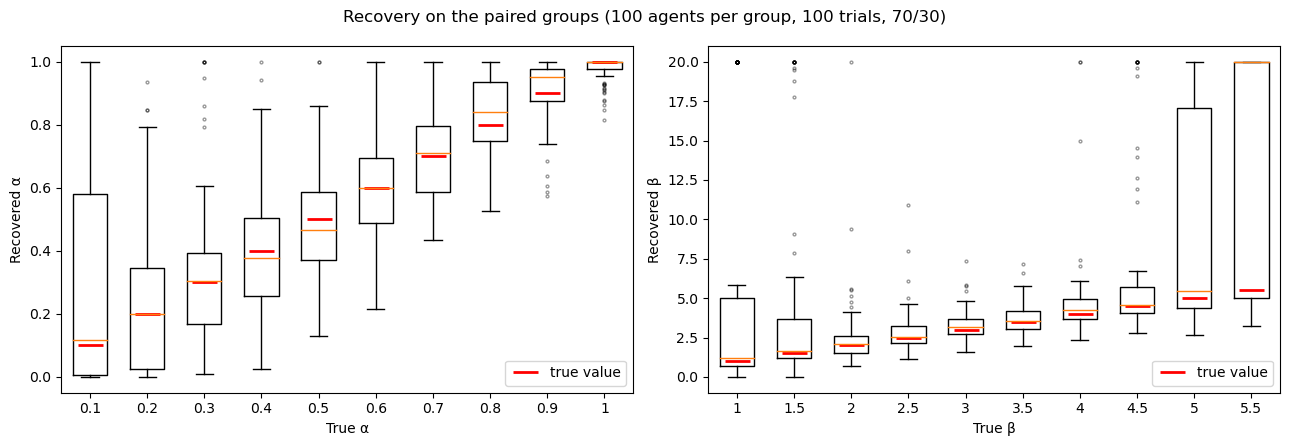

,,alpha_median,alpha_sd,beta_median,beta_sd
alpha_true,beta_true,,,,
0.1,1.0,0.12,0.35,1.19,7.96
0.2,1.5,0.20,0.23,1.68,5.93
0.3,2.0,0.30,0.22,2.08,2.16
0.4,2.5,0.38,0.19,2.50,1.32
0.5,3.0,0.47,0.17,3.17,0.90
0.6,3.5,0.60,0.16,3.55,0.96
0.7,4.0,0.71,0.14,4.27,2.61
0.8,4.5,0.84,0.12,4.57,4.70
0.9,5.0,0.95,0.10,5.46,6.71


In [6]:
def boxplot_by_true(ax, results, true_col, hat_col, label):
    values = sorted(results[true_col].unique())
    ax.boxplot([results.loc[results[true_col] == v, hat_col] for v in values],
               positions=range(len(values)), widths=0.6, showfliers=True,
               flierprops={"markersize": 2, "alpha": 0.4})
    ax.plot(range(len(values)), values, "r_", markersize=18, markeredgewidth=2, label="true value")
    ax.set_xticks(range(len(values)))
    ax.set_xticklabels([f"{v:g}" for v in values])
    ax.set_xlabel(f"True {label}")
    ax.set_ylabel(f"Recovered {label}")
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
boxplot_by_true(axes[0], paired, "alpha_true", "alpha_hat", "α")
boxplot_by_true(axes[1], paired, "beta_true", "beta_hat", "β")
fig.suptitle("Recovery on the paired groups (100 agents per group, 100 trials, 70/30)")
fig.tight_layout()
fig.savefig(f"{OUT}/recovery_paired_groups.png", dpi=150)
plt.show()

paired.groupby(["alpha_true", "beta_true"]).agg(
    alpha_median=("alpha_hat", "median"), alpha_sd=("alpha_hat", "std"),
    beta_median=("beta_hat", "median"), beta_sd=("beta_hat", "std")).round(2)

## 3. Parameter recovery on a crossed α × β grid

In the paired groups α and β rise together, so a correlation between true and recovered α could not be separated
from one driven by β. Here every α is crossed with every β (10 × 10 cells, 30 agents per cell).

In [7]:
# Same recovery, but every alpha is crossed with every beta so the two
# parameters are not tied together. Still 50 trials per bandit (100 total).
AGENTS_PER_CELL = 30
grid_alpha, grid_beta = np.meshgrid(alpha_parameters, beta_parameters, indexing="ij")
crossed_alphas = np.repeat(grid_alpha.ravel(), AGENTS_PER_CELL)
crossed_betas = np.repeat(grid_beta.ravel(), AGENTS_PER_CELL)

rng = np.random.default_rng(SEED + 2)
crossed_100 = rl.run_recovery(crossed_alphas, crossed_betas, rng, trials_per_pair=50,
                              p_good=P_GOOD, p_bad=P_BAD)
crossed_100.to_csv(f"{OUT}/recovery_crossed_100_trials.csv", index=False)
pd.Series(recovery_stats(crossed_100)).round(3)


alpha_pearson          0.820
alpha_spearman         0.819
beta_pearson           0.449
beta_spearman          0.766
beta_at_upper_bound    0.041
alpha_at_a_bound       0.124
dtype: float64

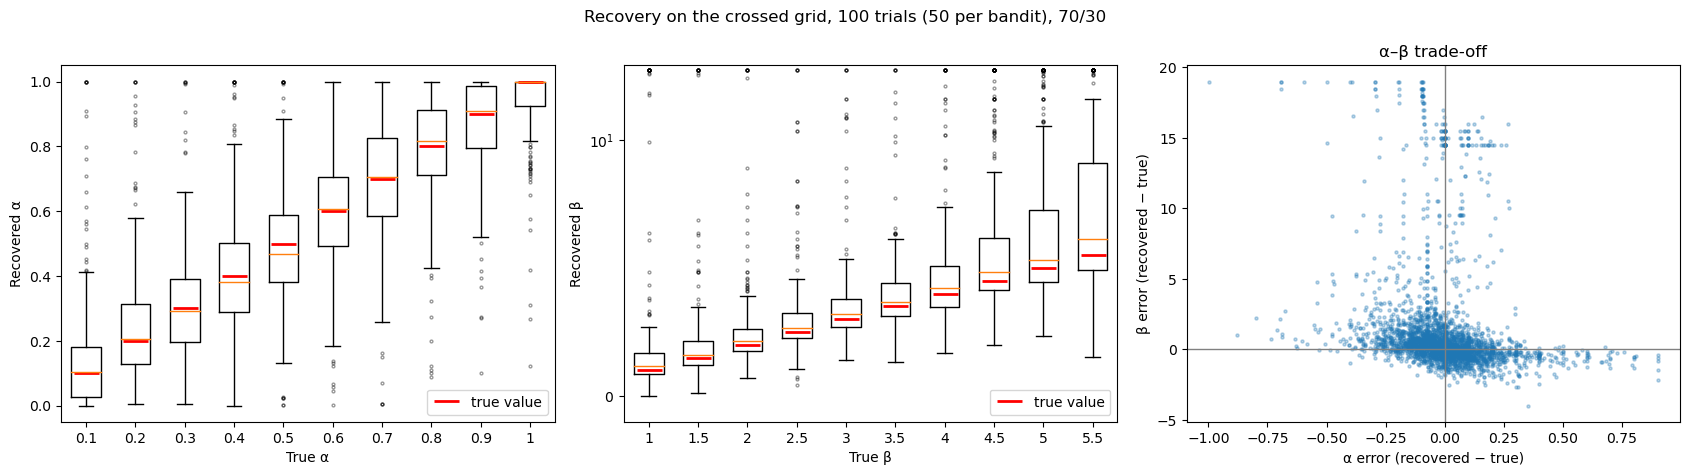

In [8]:
def plot_recovery(results, title, filename):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    boxplot_by_true(axes[0], results, "alpha_true", "alpha_hat", "α")
    boxplot_by_true(axes[1], results, "beta_true", "beta_hat", "β")
    axes[1].set_yscale("symlog", linthresh=10)
    axes[2].scatter(results["alpha_hat"] - results["alpha_true"],
                    results["beta_hat"] - results["beta_true"], s=5, alpha=0.3)
    axes[2].axhline(0, color="grey", linewidth=1)
    axes[2].axvline(0, color="grey", linewidth=1)
    axes[2].set_xlabel("α error (recovered − true)")
    axes[2].set_ylabel("β error (recovered − true)")
    axes[2].set_title("α–β trade-off")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(filename, dpi=150)
    plt.show()

plot_recovery(crossed_100, "Recovery on the crossed grid, 100 trials (50 per bandit), 70/30",
              f"{OUT}/recovery_crossed_100_trials.png")

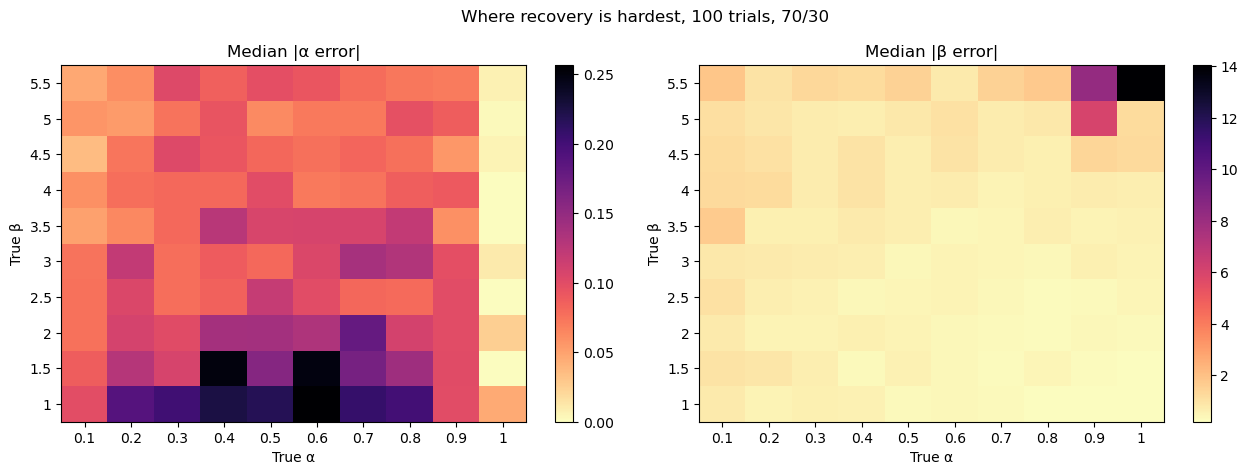

In [9]:
def plot_error_heatmaps(results, title, filename):
    cell = results.assign(alpha_abs_err=(results["alpha_hat"] - results["alpha_true"]).abs(),
                          beta_abs_err=(results["beta_hat"] - results["beta_true"]).abs())
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, column, label in [(axes[0], "alpha_abs_err", "Median |α error|"),
                              (axes[1], "beta_abs_err", "Median |β error|")]:
        table = cell.pivot_table(index="beta_true", columns="alpha_true", values=column, aggfunc="median")
        image = ax.imshow(table.values, origin="lower", aspect="auto", cmap="magma_r")
        ax.set_xticks(range(len(table.columns)))
        ax.set_xticklabels([f"{v:g}" for v in table.columns])
        ax.set_yticks(range(len(table.index)))
        ax.set_yticklabels([f"{v:g}" for v in table.index])
        ax.set_xlabel("True α")
        ax.set_ylabel("True β")
        ax.set_title(label)
        fig.colorbar(image, ax=ax)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(filename, dpi=150)
    plt.show()

plot_error_heatmaps(crossed_100, "Where recovery is hardest, 100 trials, 70/30", f"{OUT}/recovery_error_heatmap_100_trials.png")

## 4. 100 trials versus 200 trials

Same grid and same number of agents, with 100 trials per bandit instead of 50, to show what the 100-trial limit costs.

In [10]:
# Comparison only. trials_per_pair=100 means 100 shows of each bandit
# (200 trials total), which is the longer task. The task we keep is the
# 50-per-bandit run stored in crossed_100 above.
rng = np.random.default_rng(SEED + 3)
crossed_200 = rl.run_recovery(crossed_alphas, crossed_betas, rng, trials_per_pair=100,
                              p_good=P_GOOD, p_bad=P_BAD)
crossed_200.to_csv(f"{OUT}/recovery_crossed_200_trials.csv", index=False)

comparison = pd.DataFrame({"100 trials (50 per bandit)": recovery_stats(crossed_100),
                           "200 trials (100 per bandit)": recovery_stats(crossed_200)})
for name, results in [("100 trials (50 per bandit)", crossed_100), ("200 trials (100 per bandit)", crossed_200)]:
    comparison.loc["alpha_median_abs_error", name] = (results["alpha_hat"] - results["alpha_true"]).abs().median()
    comparison.loc["beta_median_abs_error", name] = (results["beta_hat"] - results["beta_true"]).abs().median()
comparison.to_csv(f"{OUT}/recovery_100_vs_200_trials.csv")
comparison.round(3)


,100 trials (50 per bandit),200 trials (100 per bandit)
alpha_pearson,0.820,0.913
alpha_spearman,0.819,0.913
beta_pearson,0.449,0.537
beta_spearman,0.766,0.886
beta_at_upper_bound,0.041,0.020
alpha_at_a_bound,0.124,0.101
alpha_median_abs_error,0.090,0.063
beta_median_abs_error,0.600,0.371


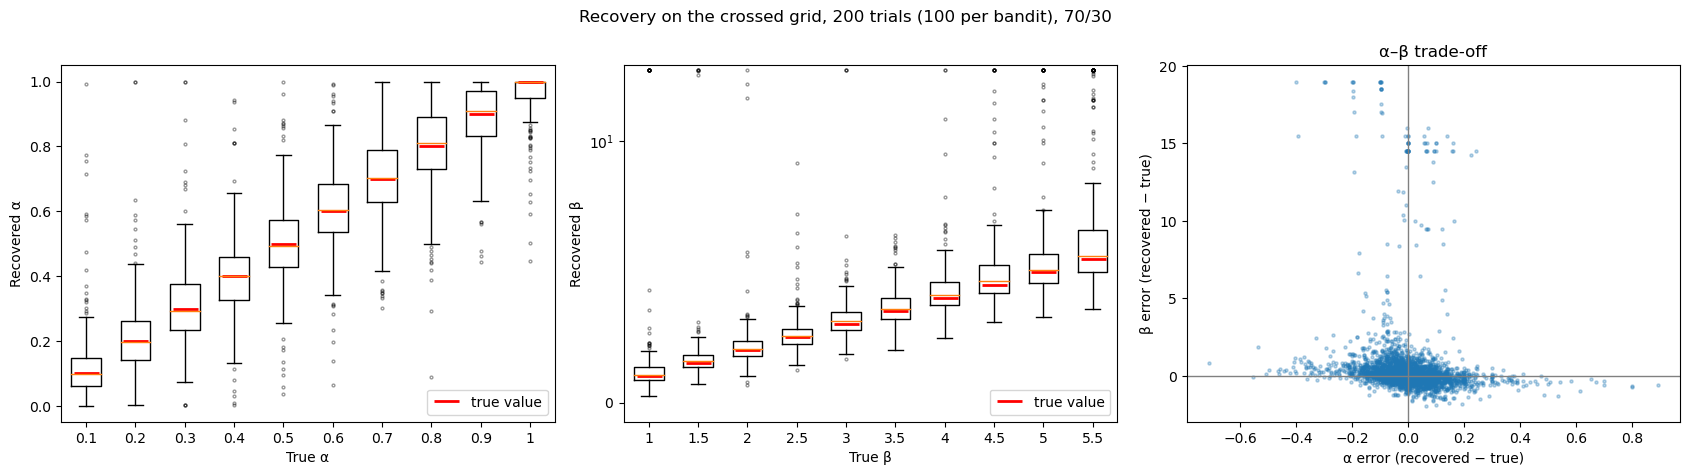

In [11]:
plot_recovery(crossed_200, "Recovery on the crossed grid, 200 trials (100 per bandit), 70/30",
              f"{OUT}/recovery_crossed_200_trials.png")